# Step 2 — kNN, CatBoost and TabM on the same LOCO design and metrics as step 1

| model | input | tuning |
|---|---|---|
| **knn** | the logistic-regression design matrix (one-hot + standardised) | k ∈ {50, 150, 400} by the inner LOCO over the training cycles |
| **catboost** | all features; the categorical features go in as CatBoost categoricals (missing and −1 are their own levels), numeric NaN handled natively | depth ∈ {4, 6} by the inner LOCO; number of trees by early stopping |
| **tabm** | all features; TabM (Gorishniy et al. 2025), numeric features quantile-normalised with a not-applicable indicator, categorical features as integer codes | none: package defaults (k = 32, 3 × 512, dropout 0.1), the authors' recommendation since deep models are costly to tune; epochs by early stopping on a stratified 15% of the training rows |

TabM runs on a GPU if one with no processes on it is free, else on CPU.

**Output:** `$NHANES_WORK/modeling/step2/` `predictions_<model>.csv.gz`, `metrics.csv`, `chosen_params.json`, `report.txt` (also compares with step 1)

`RUN = True` retrains (kNN ≈ 30 min, CatBoost ≈ 1 h, TabM a few minutes on a GPU); `QUICK = True` with it runs one outer fold, the smallest grids and 3 TabM epochs, written to `step2_quick/`. `MODELS` picks which to run. `RUN = False` only shows the saved results.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.paths import RESULTS, THREADS  # noqa: E402

RUN = False    # True: retrain and overwrite $NHANES_WORK/modeling/step2
QUICK = False  # with RUN: one outer fold, smallest grids, 3 TabM epochs (written to step2_quick/)
MODELS = ["knn", "catboost", "tabm"]
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
QUICK = QUICK or os.environ.get("NHANES_QUICK") == "1"
OUT = RESULTS / ("step2_quick" if RUN and QUICK else "step2")

## kNN and TabM (CatBoost is in `nhanes/loco.py`, shared with step 6)

In [2]:
if RUN:
    import torch
    from joblib import Parallel, delayed
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.preprocessing import QuantileTransformer

    from nhanes import loco
    from nhanes.loco import FEAT, NOT_FEATURES, SEED, free_gpu, logreg_matrix, metrics, run_catboost

    KNN_GRID = [50, 150, 400]
    TABM = dict(lr=2e-3, weight_decay=3e-4, batch=256, max_epochs=100, patience=16)

    # ---------------- kNN ----------------
    def _knn_auc(Xtr, ytr, Xva, yva, k):
        return roc_auc_score(yva, KNeighborsClassifier(n_neighbors=k).fit(Xtr, ytr).predict_proba(Xva)[:, 1])

    def run_knn(data, train_cycles, test_c, dic):
        jobs = []
        for val_c in train_cycles:
            tr, va = data[data.cycle.isin(train_cycles) & (data.cycle != val_c)], data[data.cycle == val_c]
            A, B = logreg_matrix(tr.drop(columns=NOT_FEATURES), va.drop(columns=NOT_FEATURES), dic)
            jobs += [(k, delayed(_knn_auc)(A, tr.depression, B, va.depression, k)) for k in KNN_GRID]
        scores = {k: [] for k in KNN_GRID}
        for (k, _), auc in zip(jobs, Parallel(n_jobs=THREADS)(j for _, j in jobs)):
            scores[k].append(auc)
        k = max(scores, key=lambda k: np.mean(scores[k]))
        tr, te = data[data.cycle != test_c], data[data.cycle == test_c]
        A, B = logreg_matrix(tr.drop(columns=NOT_FEATURES), te.drop(columns=NOT_FEATURES), dic)
        prob = KNeighborsClassifier(n_neighbors=k, n_jobs=THREADS).fit(A, tr.depression).predict_proba(B)[:, 1]
        return prob, {"n_neighbors": k, "inner_auroc": round(float(np.mean(scores[k])), 4)}

    # ---------------- TabM ----------------
    def tabm_arrays(train, test, dic):
        """Quantile-normal numeric features (+ not-applicable indicators) and integer-coded categoricals."""
        feats = [c for c in train if c not in NOT_FEATURES]
        cat = [c for c in feats if dic.get(c) == "categorical"]
        num = [c for c in feats if c not in cat]
        na = [c for c in num if (train[c] == -1).any()]

        def numeric(df):
            x = df[num].mask(df[num] == -1)
            return pd.concat([x, (df[na] == -1).astype(float).add_suffix("__na")], axis=1)

        ntr, nte = numeric(train), numeric(test)
        med = ntr.median()
        ntr, nte = ntr.fillna(med), nte.fillna(med)
        qt = QuantileTransformer(output_distribution="normal", n_quantiles=1000, subsample=10**9, random_state=SEED)
        xtr, xte = qt.fit_transform(ntr).astype(np.float32), qt.transform(nte).astype(np.float32)
        ctr, cte, card = [], [], []
        for c in cat:
            levels = {v: i for i, v in enumerate(sorted(train[c].fillna(-99).unique()))}
            ctr.append(train[c].fillna(-99).map(levels).to_numpy())
            cte.append(test[c].fillna(-99).map(levels).fillna(len(levels)).to_numpy())  # unseen level
            card.append(len(levels) + 1)
        return xtr, xte, np.stack(ctr, 1).astype(np.int64), np.stack(cte, 1).astype(np.int64), card

    def tabm_predict(model, x, c, device):
        model.eval()
        out = []
        with torch.no_grad():
            for i in range(0, len(x), 4096):
                logit = model(torch.as_tensor(x[i:i + 4096], device=device), torch.as_tensor(c[i:i + 4096], device=device))
                out.append(torch.sigmoid(logit.squeeze(-1)).mean(1).cpu().numpy())  # mean over the k heads
        return np.concatenate(out)

    def run_tabm(data, train_cycles, test_c, dic, device):
        import tabm
        torch.manual_seed(SEED)
        tr, te = data[data.cycle != test_c], data[data.cycle == test_c]
        fit_idx, es_idx = train_test_split(np.arange(len(tr)), test_size=0.15, stratify=tr.depression, random_state=SEED)
        fit, es = tr.iloc[fit_idx], tr.iloc[es_idx]
        xf, xe, cf, ce, card = tabm_arrays(fit, es, dic)
        _, xt, _, ct, _ = tabm_arrays(fit, te, dic)
        yf = torch.as_tensor(fit.depression.to_numpy(), dtype=torch.float32, device=device)
        model = tabm.TabM.make(n_num_features=xf.shape[1], cat_cardinalities=card, d_out=1).to(device)
        opt = torch.optim.AdamW(model.parameters(), lr=TABM["lr"], weight_decay=TABM["weight_decay"])
        pos_w = torch.tensor((len(yf) - yf.sum().item()) / yf.sum().item(), device=device)
        xf_t, cf_t = torch.as_tensor(xf, device=device), torch.as_tensor(cf, device=device)
        best, best_state, bad, epoch = -1.0, None, 0, 0
        for epoch in range(1, TABM["max_epochs"] + 1):
            model.train()
            for b in torch.randperm(len(yf), device=device).split(TABM["batch"]):
                logit = model(xf_t[b], cf_t[b]).squeeze(-1)  # (batch, k): each head trained on its own loss
                y = yf[b].unsqueeze(1).expand_as(logit)
                loss = torch.nn.functional.binary_cross_entropy_with_logits(logit, y, pos_weight=pos_w)
                opt.zero_grad()
                loss.backward()
                opt.step()
            auc = roc_auc_score(es.depression, tabm_predict(model, xe, ce, device))
            if auc > best:
                best, bad = auc, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= TABM["patience"]:
                    break
        model.load_state_dict(best_state)
        prob = tabm_predict(model, xt, ct, device)
        return prob, {"epochs_run": epoch, "early_stop_auroc": round(best, 4), "device": str(device)}

## Run

In [3]:
if RUN:
    OUT.mkdir(parents=True, exist_ok=True)
    data = pd.read_csv(FEAT / "features_2005_2018.csv.gz")
    dic = pd.read_csv(FEAT / "feature_dictionary.csv").set_index("column").type.to_dict()
    cycles = sorted(data.cycle.unique())
    outer = cycles[:1] if QUICK else cycles
    if QUICK:
        KNN_GRID[:] = KNN_GRID[:1]
        loco.CAT_GRID[:] = loco.CAT_GRID[:1]
        TABM["max_epochs"] = 3
    device = torch.device("cpu")
    torch.set_num_threads(THREADS)

    met_path, par_path = OUT / "metrics.csv", OUT / "chosen_params.json"
    rows = pd.read_csv(met_path).to_dict("records") if met_path.exists() and not QUICK else []
    chosen = json.loads(par_path.read_text()) if par_path.exists() and not QUICK else {}
    for model in MODELS:
        if model == "tabm":  # checked when TabM starts: it runs last, hours after launch
            gpu = free_gpu()
            device = torch.device(f"cuda:{gpu}" if gpu is not None else "cpu")
        rows = [r for r in rows if r["model"] != model]
        preds = []
        for test_c in outer:
            t0 = time.time()
            train_cycles = [c for c in cycles if c != test_c]
            if model == "knn":
                prob, params = run_knn(data, train_cycles, test_c, dic)
            elif model == "catboost":
                prob, params = run_catboost(data, train_cycles, test_c, dic)
            else:
                prob, params = run_tabm(data, train_cycles, test_c, dic, device)
            te = data[data.cycle == test_c]
            chosen[f"{model}|{test_c}"] = params
            preds.append(pd.DataFrame({"SEQN": te.SEQN, "cycle": test_c, "model": model,
                                       "depression": te.depression, "weight": te.WTMEC2YR, "prob": prob}))
            rows.append({"model": model, "test_cycle": test_c, **metrics(te.depression, prob, te.WTMEC2YR),
                         "minutes": round((time.time() - t0) / 60, 1)})
            print(f"{test_c} {model}: AUROC {rows[-1]['auroc']:.3f}  {params}  {rows[-1]['minutes']} min", flush=True)
        pd.concat(preds).to_csv(OUT / f"predictions_{model}.csv.gz", index=False)
        pd.DataFrame(rows).to_csv(met_path, index=False)
        par_path.write_text(json.dumps(chosen, indent=1))

    met = pd.DataFrame(rows)
    step1 = RESULTS / "step1" / "metrics.csv"
    if step1.exists():
        met = pd.concat([pd.read_csv(step1), met], ignore_index=True)
    order = ["logreg", "knn", "xgboost", "catboost", "tabm"]
    summ = met.groupby("model")[["auroc", "auroc_weighted", "auprc", "brier"]].agg(["mean", "std"]).round(3)
    summ = summ.reindex([m for m in order if m in summ.index])
    per = met.pivot(index="test_cycle", columns="model", values="auroc").round(3)
    per = per[[m for m in order if m in per.columns]]
    lines = ["leave-one-cycle-out, outcome PHQ-9 >= 10; step 1 (logreg, xgboost) + step 2", "",
             "mean (sd) over test cycles, each cycle weighted equally:", summ.to_string(), "",
             "AUROC per test cycle:", per.to_string(), "",
             f"TabM device: {device}"]
    (OUT / "report.txt").write_text("\n".join(lines) + "\n")

## Results (with step 1)

In [4]:
print((OUT / "report.txt").read_text())

leave-one-cycle-out, outcome PHQ-9 >= 10; step 1 (logreg, xgboost) + step 2

mean (sd) over test cycles, each cycle weighted equally:
          auroc        auroc_weighted         auprc         brier       
           mean    std           mean    std   mean    std   mean    std
model                                                                   
logreg    0.874  0.011          0.877  0.018  0.481  0.036  0.137  0.007
knn       0.802  0.010          0.802  0.011  0.348  0.035  0.075  0.011
xgboost   0.871  0.010          0.875  0.016  0.481  0.032  0.129  0.005
catboost  0.873  0.010          0.877  0.016  0.482  0.033  0.133  0.009
tabm      0.872  0.011          0.875  0.017  0.481  0.033  0.141  0.025

AUROC per test cycle:
model       logreg    knn  xgboost  catboost   tabm
test_cycle                                         
2005-06      0.894  0.792    0.888     0.890  0.889
2007-08      0.877  0.798    0.874     0.876  0.875
2009-10      0.866  0.792    0.865     0.866  0.859

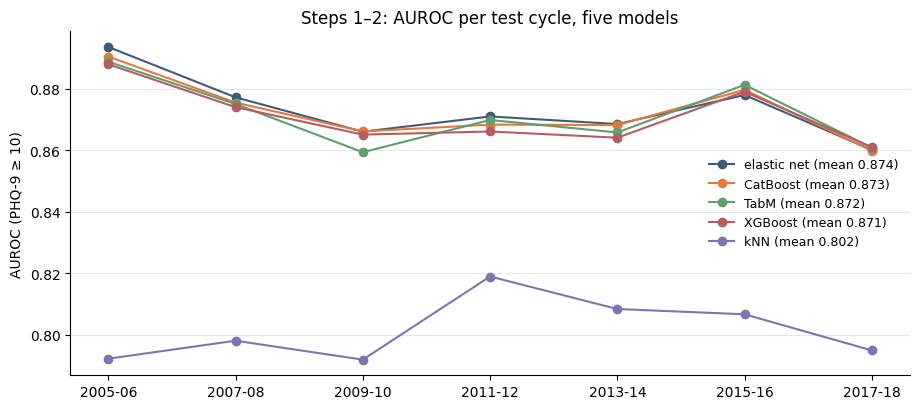

In [5]:
met = pd.concat([pd.read_csv(RESULTS / "step1" / "metrics.csv"), pd.read_csv(OUT / "metrics.csv")], ignore_index=True)
names = {"logreg": "elastic net", "xgboost": "XGBoost", "catboost": "CatBoost", "tabm": "TabM", "knn": "kNN"}
plots.per_split_auroc(met, models=["logreg", "catboost", "tabm", "xgboost", "knn"], labels=names,
                      title="Steps 1–2: AUROC per test cycle, five models")
plots.show()